# Hollow (ring) images and the Korolev size factor

**A drop far from the probe's object plane images as a ring wider than the drop; one chain divides its size by the Korolev (2007) size factor, another keeps the ring size, and the same drop lands in different bins.** In the synthetic population below, uncorrected rings are reported at a median 1.46 times their true size against 0.91 corrected, and the 900–1000 µm bin differs by +7.4 dB between the two chains. The "Key results" cell after section 4 recomputes the three figures above from the executed arrays and fails if any differs at two decimals. The check reads three per-particle variables already in the file and compares two histograms.

**What you get**

- the package's own hollow test (`arrayprobe_uiops.reject.is_it_hollow`) and Korolev lookup on synthetic rings;
- each particle's size before and after correction, and the large-bin difference in dB;
- the variables to read from your own files to rebuild both size distributions.

> **Every number in this notebook is synthetic**, drawn from a fixed-seed random-number generator in section 2; no data file is read.

**Before this:** [05_triage_and_gallery](../1_getting_started/05_triage_and_gallery.ipynb) (Looking at particles: a contact sheet, a gallery, and the triage page). **Related:** [15_hollow_rings](15_hollow_rings.ipynb). **Needs:** `pip install "arrayprobe[extra]"` (matplotlib) (`pip install "arrayprobe[zarr]"` adds an optional section).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/5_data_quality/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

Import the package's hollow-image test and its size-correction lookups, then define two helpers. One draws the shadow of a ring of a chosen diameter and hole size; the other runs the hollow test on a shadow and returns whether it is hollow and the factor its size would be divided by.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
# _z_d_lookup and _edge_0_lookup are internal helpers (the Korolev 2007 tables), imported here to show the lookup.
from arrayprobe_uiops.reject import is_it_hollow, _z_d_lookup, _edge_0_lookup

DIODE_UM = 10.0  # synthetic probe pixel size
def ring_image(d_um, hole_frac, n_diodes=128):
    """Shadow (True = shaded) of a disk of diameter d_um with a centred hole hole_frac x d."""
    r = d_um / DIODE_UM / 2
    n = int(np.ceil(2 * r)) + 4
    y, x = np.mgrid[:n, :n_diodes]
    rr = np.hypot(y - n / 2 + 0.5, x - n_diodes / 2 + 0.5)
    return (rr < r) & (rr >= r * hole_frac)

def korolev(shadow):
    """(hollow, size_factor) from the package's hollow test and the Korolev tables."""
    status, edge, hole = is_it_hollow(shadow, shadow.shape[0])
    if status != 1 or edge <= 0 or hole <= 1:
        return 0, 1.0
    return 1, _edge_0_lookup(_z_d_lookup(hole / edge))
print(f'setup: {is_it_hollow.__module__}.is_it_hollow and the Korolev lookups imported; synthetic probe pixel {DIODE_UM:.0f} µm')


setup: arrayprobe_uiops.reject.is_it_hollow and the Korolev lookups imported; synthetic probe pixel 10 µm


## 1. What a ring looks like to the hollow test

Six synthetic particles of 400 µm imaged diameter, from in focus (no hole) to far out of focus (a
large hole). The title of each panel gives the hollow flag, the hole-to-edge ratio's size factor and
the corrected size.

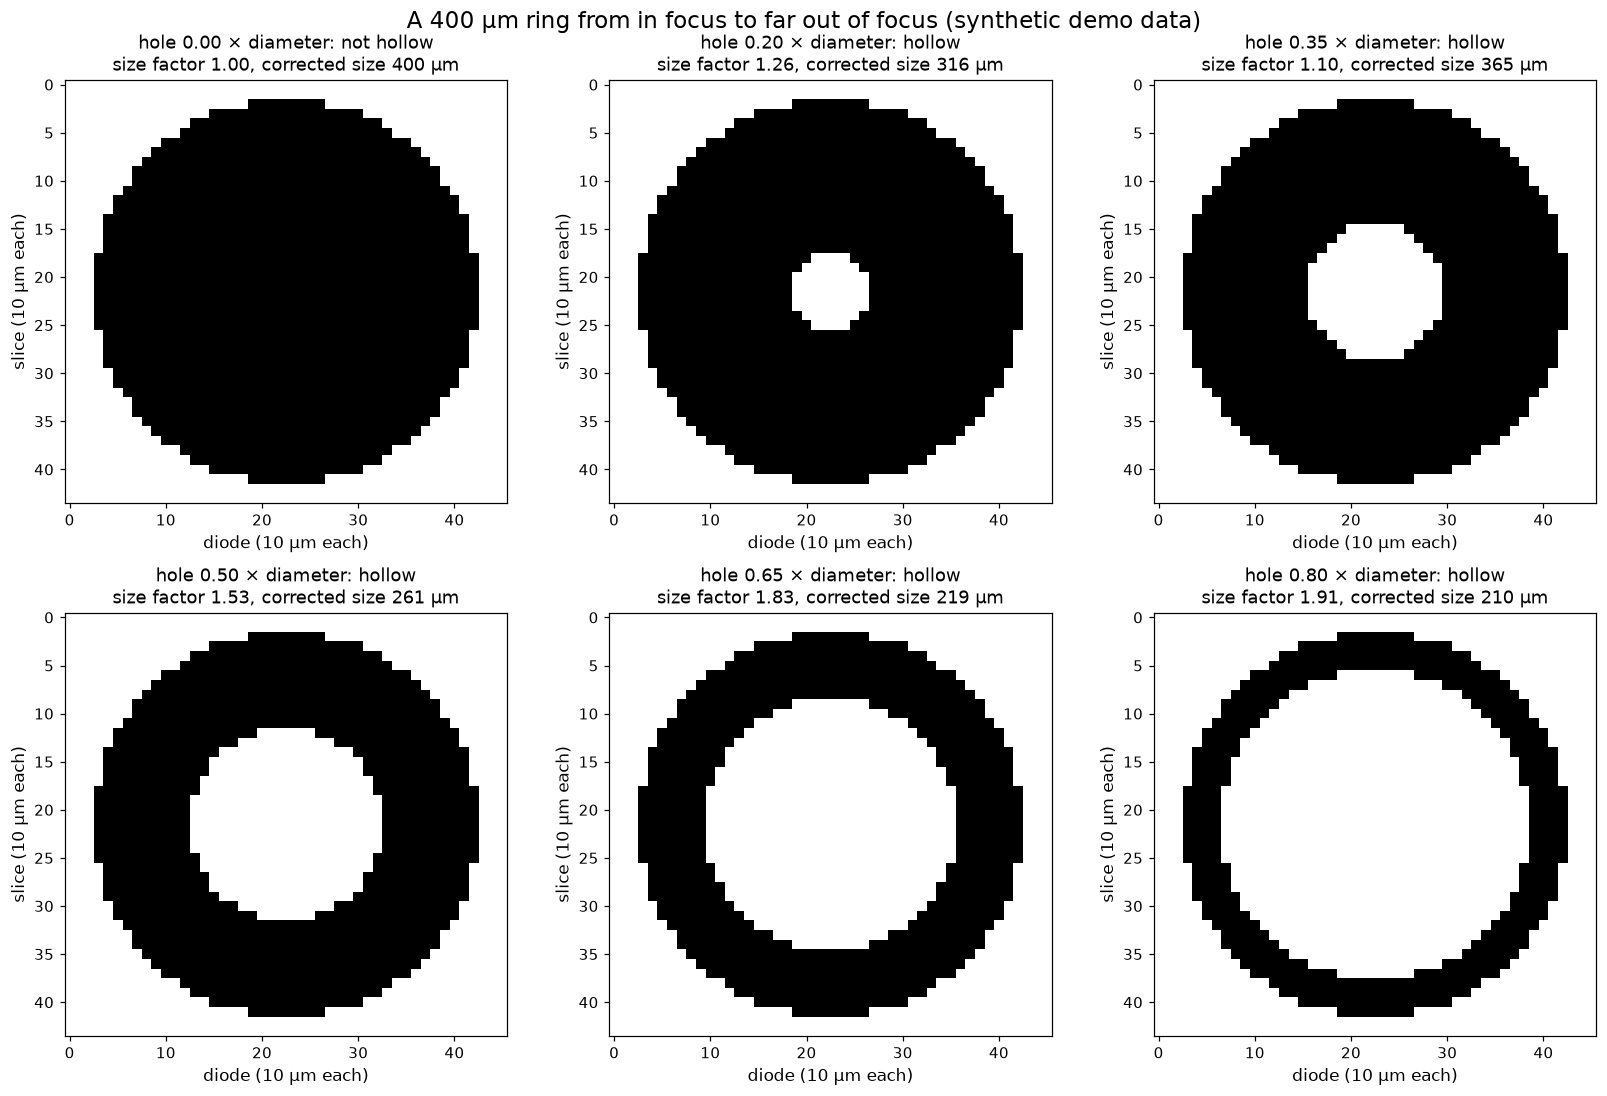

In [3]:
fracs = [0.0, 0.2, 0.35, 0.5, 0.65, 0.8]
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('A 400 µm ring from in focus to far out of focus (synthetic demo data)', fontsize=15)
for ax, f in zip(axes.flat, fracs):
    img = ring_image(400, f)
    cols = np.where(img.any(axis=0))[0]
    h, sf = korolev(img)
    ax.imshow(img[:, cols[0] - 3:cols[-1] + 4], cmap='gray_r', interpolation='nearest')
    ax.set_title(f'hole {f:.2f} × diameter: ' + ('hollow' if h else 'not hollow')
                 + f'\nsize factor {sf:.2f}, corrected size {400/sf:.0f} µm', fontsize=12)
    ax.set_xlabel('diode (10 µm each)', fontsize=11); ax.set_ylabel('slice (10 µm each)', fontsize=11)
fig.tight_layout(h_pad=2.5); plt.show()

*Figure 1. Six synthetic 400 µm particles, hole fraction rising left to right and top to bottom; each panel names the hollow-test verdict, the Korolev size factor and the corrected size.*

## 2. A synthetic population: in-focus and out-of-focus drops

800 drops, exponential in true diameter (mean 200 µm). 30 % are out of focus: they image as rings
whose apparent diameter is the true diameter times a ring growth factor, with the hole fraction rising
with defocus. Chain A divides a hollow particle's size by the size factor; chain B keeps the ring size.

In [4]:
rng = np.random.default_rng(28)
N = 800
d_true = 50 + rng.exponential(200, N)
oof = rng.random(N) < 0.30
hole = np.where(oof, rng.uniform(0.3, 0.75, N), 0.0)
growth = np.where(oof, 1 + 0.9 * hole, 1.0)   # synthetic: rings image larger than the drop
d_img = d_true * growth
hollow = np.zeros(N, int); sf = np.ones(N)
for i in range(N):
    hollow[i], sf[i] = korolev(ring_image(d_img[i], hole[i]))
d_A = np.where(hollow == 1, d_img / sf, d_img)   # corrected
d_B = d_img                                       # uncorrected
print(f'out of focus: {oof.sum()}, flagged hollow: {hollow.sum()}, '
      f'flagged among in-focus: {hollow[~oof].sum()}')
assert hollow[~oof].sum() == 0 and hollow[oof].sum() > 0.8 * oof.sum()

out of focus: 249, flagged hollow: 249, flagged among in-focus: 0


## 3. Size before and after correction

median reported/true, hollow particles: chain A 0.91, chain B 1.46


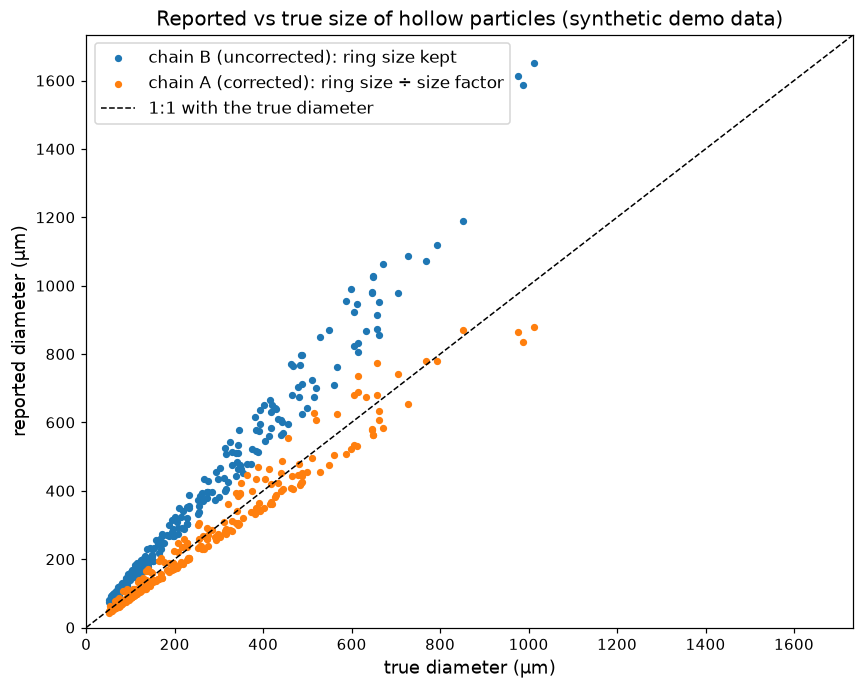

In [5]:
fig, ax = plt.subplots(figsize=(9, 7))
m = hollow == 1
ax.scatter(d_true[m], d_B[m], s=14, label='chain B (uncorrected): ring size kept')
ax.scatter(d_true[m], d_A[m], s=14, label='chain A (corrected): ring size ÷ size factor')
lim = 1.05 * max(d_true[m].max(), d_B[m].max(), d_A[m].max())
ax.plot([0, lim], [0, lim], 'k--', lw=1, label='1:1 with the true diameter')
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_title('Reported vs true size of hollow particles (synthetic demo data)', fontsize=13)
ax.set_xlabel('true diameter (µm)', fontsize=12); ax.set_ylabel('reported diameter (µm)', fontsize=12)
ax.legend(fontsize=11); plt.show()
print(f'median reported/true, hollow particles: chain A {np.median(d_A[m]/d_true[m]):.2f}, '
      f'chain B {np.median(d_B[m]/d_true[m]):.2f}')

*Figure 2. Reported against true diameter for the particles flagged hollow: chain B keeps the ring size, chain A divides it by the Korolev size factor; dashed line 1:1. Synthetic demo data.*

## 4. The large bins of the size distribution

The same 800 drops binned by each chain's size. The difference is quoted in dB per bin,
$10\log_{10}(B / A)$, where both bins are non-empty.

 400- 500 µm: A= 69 B= 62  B vs A  -0.5 dB
 500- 600 µm: A= 52 B= 61  B vs A  +0.7 dB
 600- 700 µm: A= 33 B= 40  B vs A  +0.8 dB
 700- 800 µm: A= 12 B= 17  B vs A  +1.5 dB
 800- 900 µm: A=  7 B= 11  B vs A  +2.0 dB
 900-1000 µm: A=  2 B= 11  B vs A  +7.4 dB
1000-1100 µm: A=  2 B=  7  B vs A  +5.4 dB
1300-1400 µm: A=  2 B=  2  B vs A  +0.0 dB
1500-1600 µm: A=  1 B=  2  B vs A  +3.0 dB


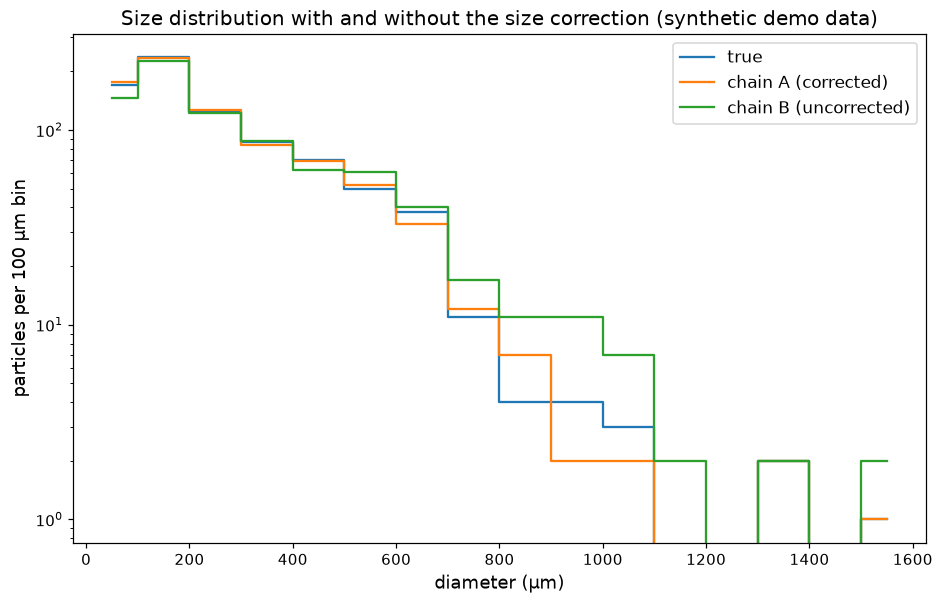

In [6]:
edges = np.arange(0, 1601, 100)
nA, _ = np.histogram(d_A, edges); nB, _ = np.histogram(d_B, edges); nT, _ = np.histogram(d_true, edges)
mid = 0.5 * (edges[1:] + edges[:-1])
fig, ax = plt.subplots(figsize=(10, 6))
ax.step(mid, nT, where='mid', label='true'); ax.step(mid, nA, where='mid', label='chain A (corrected)')
ax.step(mid, nB, where='mid', label='chain B (uncorrected)')
ax.set_yscale('log'); ax.set_xlabel('diameter (µm)', fontsize=12); ax.set_ylabel('particles per 100 µm bin', fontsize=12)
ax.set_title('Size distribution with and without the size correction (synthetic demo data)', fontsize=13)
ax.legend(fontsize=11)
plt.show()
for lo, a, b in zip(edges[:-1], nA, nB):
    if lo >= 400 and a > 0 and b > 0:
        print(f'{lo:4d}-{lo+100:4d} µm: A={a:3d} B={b:3d}  B vs A {10*np.log10(b/a):+5.1f} dB')
big = d_true > 0
assert nB[edges[:-1] >= 600].sum() > nA[edges[:-1] >= 600].sum()

*Figure 3. Particle counts per 100 µm diameter bin for the true sizes, chain A (corrected) and chain B (uncorrected); log scale. Synthetic demo data.*

**Reading it.** Chain B puts out-of-focus drops in bins larger than their true size, so its large
bins are fuller than chain A's; the excess grows with size because rings are a larger share of the
counts there. Neither chain is the truth: the correction is only as good as the hollow test and the
growth model behind the Korolev tables.

In [7]:
# Key results: the figures quoted in the opening paragraph, recomputed from the arrays above.
med_A = float(np.median(d_A[m] / d_true[m])); med_B = float(np.median(d_B[m] / d_true[m]))
k900 = int(np.where(edges[:-1] == 900)[0][0])
db900 = float(10 * np.log10(nB[k900] / nA[k900]))
print(f'median reported/true, hollow particles: uncorrected {med_B:.2f}, corrected {med_A:.2f}')
print(f'900-1000 µm bin, B vs A: {db900:+.1f} dB')
assert (f'{med_B:.2f}', f'{med_A:.2f}', f'{db900:+.1f}') == ('1.46', '0.91', '+7.4'), (
    'the opening paragraph quotes 1.46, 0.91 and +7.4 dB; update it to the values printed above'
)


median reported/true, hollow particles: uncorrected 1.46, corrected 0.91
900-1000 µm bin, B vs A: +7.4 dB


The same data in xarray, which most earth-science tools read: the per-particle sizes of both chains as one `xarray.Dataset` with a named particle dimension, and the two size distributions as a second dataset on a diameter coordinate. The cell needs xarray and is skipped without it.

In [8]:
import importlib.util

# xarray is optional (pip install "arrayprobe[zarr]"); the rest of the notebook does not need it.
if importlib.util.find_spec("xarray") is not None:
    import xarray as xr

    parts = xr.Dataset(
        {
            'd_true_um': ('particle', d_true),
            'd_ring_um': ('particle', d_B),
            'd_corrected_um': ('particle', d_A),
            'hollow': ('particle', hollow),
        },
        coords={'particle': np.arange(N)},
        attrs={'note': 'synthetic population from section 2'},
    )
    sizedist = xr.Dataset(
        {'count_A_corrected': ('diameter_um', nA), 'count_B_uncorrected': ('diameter_um', nB)},
        coords={'diameter_um': mid},
    )
    print(parts)
    print(sizedist)
else:
    print("xarray is not installed; skipping the xarray view.")

<xarray.Dataset> Size: 32kB
Dimensions:         (particle: 800)
Coordinates:
  * particle        (particle) int64 6kB 0 1 2 3 4 5 ... 794 795 796 797 798 799
Data variables:
    d_true_um       (particle) float64 6kB 299.7 123.5 427.9 ... 598.9 299.2
    d_ring_um       (particle) float64 6kB 299.7 123.5 427.9 ... 598.9 299.2
    d_corrected_um  (particle) float64 6kB 299.7 123.5 427.9 ... 598.9 299.2
    hollow          (particle) int64 6kB 0 0 0 1 1 0 0 1 0 ... 0 0 0 1 0 0 0 0 0
Attributes:
    note:     synthetic population from section 2
<xarray.Dataset> Size: 384B
Dimensions:              (diameter_um: 16)
Coordinates:
  * diameter_um          (diameter_um) float64 128B 50.0 150.0 ... 1.55e+03
Data variables:
    count_A_corrected    (diameter_um) int64 128B 176 233 127 84 69 ... 0 2 0 1
    count_B_uncorrected  (diameter_um) int64 128B 146 227 122 88 62 ... 0 2 0 2


## 4b. Large-bin ratio with and without the Korolev size correction

**Takeaway: the cell below prints, per bin from 400 µm up and for everything above 600 µm together, the
count ratio between the chain without the size correction (B) and the chain with it (A), its dB
equivalent $10\log_{10}(B / A)$, and the share of each chain's bin that is hollow; a ratio far from 1 (far
from 0 dB) in a bin where the hollow share is large says the size correction, not the processing,
drives that bin's difference.** Counts are compared here, so the dB is a count ratio; a sixth-moment
(Z) comparison would be quoted in dBZ differences, $10\log_{10}(Z_B / Z_A)$, computed the same way.

On your own data, run section 5's check on one particle-by-particle file: it rebuilds both chains
from the same particles, so a large-bin ratio of 1 (0 dB) means hollow correction cannot explain a
difference you see between engines, and a large ratio means it can.

In [9]:
def bin_table(d_corr, d_unc, is_hollow, edges, lo_um=400):
    """Per-bin counts with (A) and without (B) the size correction, B/A, dB and hollow share."""
    nA_, _ = np.histogram(d_corr, edges); nB_, _ = np.histogram(d_unc, edges)
    hA_, _ = np.histogram(d_corr[is_hollow], edges); hB_, _ = np.histogram(d_unc[is_hollow], edges)
    rows = []
    for k, lo in enumerate(edges[:-1]):
        if lo < lo_um or nA_[k] == 0 or nB_[k] == 0:
            continue
        rows.append((lo, nA_[k], nB_[k], nB_[k] / nA_[k], 10 * np.log10(nB_[k] / nA_[k]),
                     hA_[k] / nA_[k], hB_[k] / nB_[k]))
    return rows

is_h = hollow == 1
print(' bin (um)     A     B   B/A     dB  hollow share A  hollow share B')
for lo, a, b, r, db, sa, sb in bin_table(d_A, d_B, is_h, edges):
    print(f'{lo:4d}-{lo+100:4d} {a:5d} {b:5d} {r:5.2f} {db:+6.1f}  {sa:14.2f}  {sb:14.2f}')
big_A = int((d_A >= 600).sum()); big_B = int((d_B >= 600).sum())
ratio_big = big_B / big_A
print(f'all particles >= 600 µm: A={big_A}, B={big_B}, B/A = {ratio_big:.2f} '
      f'({10*np.log10(ratio_big):+.1f} dB)')
# Control: without hollow particles the two chains are the same population, so the ratio is 1 (0 dB).
nA0, _ = np.histogram(d_A[~is_h], edges); nB0, _ = np.histogram(d_B[~is_h], edges)
assert np.array_equal(nA0, nB0)
print('control, hollow particles removed: B/A = 1.00 (+0.0 dB) in every bin')
assert ratio_big > 1

 bin (um)     A     B   B/A     dB  hollow share A  hollow share B
 400- 500    69    62  0.90   -0.5            0.36            0.29
 500- 600    52    61  1.17   +0.7            0.21            0.33
 600- 700    33    40  1.21   +0.8            0.30            0.42
 700- 800    12    17  1.42   +1.5            0.42            0.59
 800- 900     7    11  1.57   +2.0            0.57            0.73
 900-1000     2    11  5.50   +7.4            0.00            0.82
1000-1100     2     7  3.50   +5.4            0.00            0.71
1300-1400     2     2  1.00   +0.0            0.00            0.00
1500-1600     1     2  2.00   +3.0            0.00            0.50
all particles >= 600 µm: A=59, B=94, B/A = 1.59 (+2.0 dB)
control, hollow particles removed: B/A = 1.00 (+0.0 dB) in every bin


## 5. Check your own data

In a particle-by-particle file written by `arrayprobe_uiops` (v3.5 engine), read per particle:

- `image_hollow` (1 = the hollow test found a hole),
- `image_diam_minR` (mm; already divided by `size_factor` when the reject code is `'H'`),
- `size_factor` (the Korolev factor, 1 when no correction was applied),
- `image_auto_reject` (ASCII reject code; 72 = `'H'`, a corrected hollow particle).

The uncorrected size is `image_diam_minR * size_factor` on those particles. (Note:
`image_diam_minR_uncorrected` is a different correction, the stray-pixel one, not this.) Compare
both size columns' histograms the way section 4 does.

In [10]:
from pathlib import Path
PROC = Path('path/to/your/proc_file.nc')   # placeholder: a particle-by-particle file

def hollow_size_check(path, edges_um=np.arange(0, 2001, 100)):
    import netCDF4
    with netCDF4.Dataset(path) as nc:
        d = np.asarray(nc['image_diam_minR'][:], float) * 1000.0
        sf_ = np.asarray(nc['size_factor'][:], float)
        rej = np.asarray(nc['image_auto_reject'][:])
    corr = rej == ord('H')
    d_unc = np.where(corr, d * sf_, d)
    a, _ = np.histogram(d, edges_um); b, _ = np.histogram(d_unc, edges_um)
    print(f'{corr.sum()} of {d.size} particles size-corrected as hollow')
    for lo, x, y in zip(edges_um[:-1], a, b):
        if x and y and x != y:
            print(f'{lo:5d} µm: corrected {x}, uncorrected {y}, {10*np.log10(y/x):+.1f} dB')

if PROC.exists():
    hollow_size_check(PROC)
else:
    print('Set PROC to one of your files to run the check.')

Set PROC to one of your files to run the check.
